In [3]:
from sklearn import datasets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

I want to load 'iris dataset' and implement some algorithms on it

In [4]:
iris = datasets.load_iris()


In [5]:
iris.data.shape

(150, 4)

features:

اطلاعات یا ویژگی‌هایی هستند که مدل بر اساس آن‌ها یاد می‌گیرد. این‌ها ورودی‌های مدل هستند.

In [6]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

target:

برچسب یا خروجی‌ای هست که مدل باید پیش‌بینی کند. این همون چیزیه که می‌خوایم مدل یاد بگیره تا با دیدن ویژگی‌ها، بتونه اونو حدس بزنه.

In [7]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

Describing data:

In [8]:
iris.DESCR

'.. _iris_dataset:\n\nIris plants dataset\n--------------------\n\n**Data Set Characteristics:**\n\n:Number of Instances: 150 (50 in each of three classes)\n:Number of Attributes: 4 numeric, predictive attributes and the class\n:Attribute Information:\n    - sepal length in cm\n    - sepal width in cm\n    - petal length in cm\n    - petal width in cm\n    - class:\n            - Iris-Setosa\n            - Iris-Versicolour\n            - Iris-Virginica\n\n:Summary Statistics:\n\n============== ==== ==== ======= ===== ====================\n                Min  Max   Mean    SD   Class Correlation\n============== ==== ==== ======= ===== ====================\nsepal length:   4.3  7.9   5.84   0.83    0.7826\nsepal width:    2.0  4.4   3.05   0.43   -0.4194\npetal length:   1.0  6.9   3.76   1.76    0.9490  (high!)\npetal width:    0.1  2.5   1.20   0.76    0.9565  (high!)\n============== ==== ==== ======= ===== ====================\n\n:Missing Attribute Values: None\n:Class Distribution: 

چاپ داده به صورت آرایه:

In [9]:
iris.data

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

تبدیل داده به دیتافریم:

In [10]:
iris_df = pd.DataFrame(iris.data,columns = iris.feature_names)

In [11]:
iris_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


یک ستون به نام تارگت برای یادگیری مدل مان به دیتا فریم اضافه میکنیم:

In [12]:
iris_df['target'] = iris.target

In [13]:
iris_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


بررسی ارتباط آماری بین ویژگی های مختلف موجود در دیتاست:

In [14]:
# pd.plotting.scatter_matrix(iris_df,c = iris.target,s = 150,figsize=(11,11))
# plt.show()

## KNN algorithm:

In [15]:
from sklearn.neighbors import KNeighborsClassifier

In [16]:
x = iris.data
y = iris.target

In [17]:
x

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [18]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [19]:
knn = KNeighborsClassifier(n_neighbors = 6,metric = 'minkowski',p = 2)
knn.fit(x,y)


KNeighborsClassifier(n_neighbors=6)

In [20]:
y_predict = knn.predict(np.array([[5,3,1,0.2]]))

In [21]:
y_predict #setosa

array([0])

## model training:

برای بررسی عملکرد الگوریتم مان می‌توانیم بخشی از داده را برای train کردن مدل استفاده کنیم:

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,shuffle=True,stratify=y)

In [24]:
knn = KNeighborsClassifier(n_neighbors = 6, metric = 'minkowski',p = 2)
knn.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=6)

میزان دقت الگوریتم مان را با کد زیر اندازه گیری می‌کنیم:

In [25]:
knn.score(x_test,y_test)

0.9333333333333333

بررسی ارتباط بین دقت الگوریتم کا امین همسایه نزدیک و تعداد همسایه های در نظر گرفته شده

In [26]:
neighbors = np.arange(1,30)
train_accuracy = np.empty(len(neighbors))
test_accuracy = np.empty(len(neighbors))
for i , k in enumerate(neighbors):
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(x_train,y_train)
    train_accuracy[i] = knn_model.score(x_train,y_train)
    test_accuracy[i] = knn_model.score(x_test,y_test)

In [27]:
# plt.plot(neighbors,train_accuracy,label = 'train accuracy')
# plt.plot(neighbors,test_accuracy,label = 'test accuracy')
# plt.legend()
# plt.xlabel('number of neighbors')
# plt.ylabel('Accuracy')
# plt.show()

## linear regression

In [28]:
from sklearn.linear_model import LinearRegression

In [29]:
x = np.arange(1,10)
y = np.array([28,25,26,31,32,29,30,35,36])

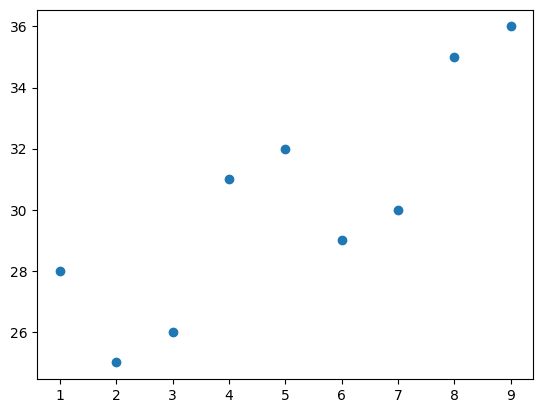

In [30]:
plt.scatter(x,y)

داده ها را به شکل ستونی در می‌آوریم تا الگوریتم های ماشین بر روی آنها قابل پیاده سازی باشند

In [31]:
x = x.reshape(-1,1)
y = y.reshape(-1,1)

رگرسیون را بر داده هایمان فیت میکنیم

In [32]:
reg = LinearRegression()
reg.fit(x,y)

LinearRegression()

In [33]:
y_predict = reg.predict(x)

In [34]:
# plt.scatter(x,y)
# plt.plot(x,y_predict)
# plt.show()

## MSE(Mean Square Error)

In [35]:
x = iris.data
y = iris.target

In [36]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.3,random_state = 42) 

In [37]:
reg = LinearRegression()
reg.fit(x_train,y_train)

LinearRegression()

In [38]:
y_pred = reg.predict(x_test)

In [39]:
from sklearn.metrics import mean_squared_error

In [40]:
mse = mean_squared_error(y_test,y_pred)
mse

0.03866591237825791

## K-fold cross validation

In [41]:
from sklearn.model_selection import cross_val_score


In [42]:
reg = LinearRegression()
cv_score = cross_val_score(reg, iris.data,iris.target,cv = 5)# cv = k

In [43]:
cv_score

array([0.        , 0.85124923, 0.        , 0.76155439, 0.        ])

In [44]:
np.mean(cv_score)

0.32256072489000853

## lasso regression

In [45]:
from sklearn.linear_model import Lasso

In [46]:
lasso = Lasso(alpha = 0.1,)
lasso.fit(iris.data, iris.target)
lasso_coef = lasso.coef_
lasso_coef

array([ 0.        , -0.        ,  0.40811896,  0.        ])

In [47]:
# plt.plot(range(4),lasso_coef)
# plt.xticks(range(4),iris.feature_names)
# plt.ylabel = ('Coefficient')

همانطور که از شکل پیداست ویژگی petal length مهم ترین ویژگی در تعیین دسته بندی گل ها است

جال می‌خواهم خطای پیش بینی مدلم را اندازه گیری کنم:

In [48]:
lasso = Lasso(alpha = 0.1)
lasso.fit(x_train,y_train)
y_lasso = lasso.predict(x_test)
lasso_mse = mean_squared_error(y_test,y_lasso)
lasso_mse

0.06496061832173458

## ridge regression

In [49]:
from sklearn.linear_model import Ridge

In [50]:
ridge = Ridge(alpha=0.1)
ridge.fit(x_train,y_train)
y_ridge = ridge.predict(x_test)
ridge_mse = mean_squared_error(y_test,y_ridge)
ridge_mse

0.03884391465304459